In [2]:
import pandas as pd
import numpy as np
import re
import string
import nltk

from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer


In [3]:
%pip install emoji

Note: you may need to restart the kernel to use updated packages.


In [4]:
df=pd.read_csv(r'E:\full stack data science\NLP\IMDB Dataset.csv')

In [5]:
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [5]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
df.tail()

,review,sentiment
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative
49999,No one expects the Star Trek movies to be high...,negative


In [7]:
df.shape

(50000, 2)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


# text preprocessing techniques--

In [9]:
# Problem 1
# Apply all the preprocessing techniques that you think are necessary

# lowercase

df['lowercase']=df['review'].str.lower()

In [10]:
df['lowercase']

0        one of the other reviewers has mentioned that ...
1        a wonderful little production. <br /><br />the...
2        i thought this was a wonderful way to spend ti...
3        basically there's a family where a little boy ...
4        petter mattei's "love in the time of money" is...
                               ...                        
49995    i thought this movie did a down right good job...
49996    bad plot, bad dialogue, bad acting, idiotic di...
49997    i am a catholic taught in parochial elementary...
49998    i'm going to have to disagree with the previou...
49999    no one expects the star trek movies to be high...
Name: lowercase, Length: 50000, dtype: str

In [11]:
# remove html tags
from bs4 import BeautifulSoup

def remove_html(text):
    return BeautifulSoup(text, 'html.parser').get_text()

df['remove_html'] = df['lowercase'].apply(remove_html)

In [12]:
df['remove_html']

0        one of the other reviewers has mentioned that ...
1        a wonderful little production. the filming tec...
2        i thought this was a wonderful way to spend ti...
3        basically there's a family where a little boy ...
4        petter mattei's "love in the time of money" is...
                               ...                        
49995    i thought this movie did a down right good job...
49996    bad plot, bad dialogue, bad acting, idiotic di...
49997    i am a catholic taught in parochial elementary...
49998    i'm going to have to disagree with the previou...
49999    no one expects the star trek movies to be high...
Name: remove_html, Length: 50000, dtype: str

In [13]:
# remove urls
def remove_urls(text):
    return re.sub(r'https?://\S+|www\.\S+', '', text)

df['remove_urls'] = df['remove_html'].apply(remove_urls)

In [14]:
df['remove_urls']

0        one of the other reviewers has mentioned that ...
1        a wonderful little production. the filming tec...
2        i thought this was a wonderful way to spend ti...
3        basically there's a family where a little boy ...
4        petter mattei's "love in the time of money" is...
                               ...                        
49995    i thought this movie did a down right good job...
49996    bad plot, bad dialogue, bad acting, idiotic di...
49997    i am a catholic taught in parochial elementary...
49998    i'm going to have to disagree with the previou...
49999    no one expects the star trek movies to be high...
Name: remove_urls, Length: 50000, dtype: str

In [15]:
# remove puncuation
def remove_punctuation(text):
    return text.translate(str.maketrans('','',string.punctuation))
df['remove_punctuation']=df['remove_urls'].apply(remove_punctuation)

In [16]:
df['remove_punctuation']

0        one of the other reviewers has mentioned that ...
1        a wonderful little production the filming tech...
2        i thought this was a wonderful way to spend ti...
3        basically theres a family where a little boy j...
4        petter matteis love in the time of money is a ...
                               ...                        
49995    i thought this movie did a down right good job...
49996    bad plot bad dialogue bad acting idiotic direc...
49997    i am a catholic taught in parochial elementary...
49998    im going to have to disagree with the previous...
49999    no one expects the star trek movies to be high...
Name: remove_punctuation, Length: 50000, dtype: str

In [17]:
# remove number
def remove_numbers(text):
    return re.sub(r'\d+', '', text)

df['remove_numbers'] = df['remove_punctuation'].apply(remove_numbers)

In [18]:
df['remove_numbers']

0        one of the other reviewers has mentioned that ...
1        a wonderful little production the filming tech...
2        i thought this was a wonderful way to spend ti...
3        basically theres a family where a little boy j...
4        petter matteis love in the time of money is a ...
                               ...                        
49995    i thought this movie did a down right good job...
49996    bad plot bad dialogue bad acting idiotic direc...
49997    i am a catholic taught in parochial elementary...
49998    im going to have to disagree with the previous...
49999    no one expects the star trek movies to be high...
Name: remove_numbers, Length: 50000, dtype: str

In [19]:
# remove extra space
def remove_extra_spaces(text):
    return re.sub(r'\s+', ' ', text).strip()

df['remove_extra_spaces'] = df['remove_numbers'].apply(remove_extra_spaces)

In [20]:

df['remove_extra_spaces']

0        one of the other reviewers has mentioned that ...
1        a wonderful little production the filming tech...
2        i thought this was a wonderful way to spend ti...
3        basically theres a family where a little boy j...
4        petter matteis love in the time of money is a ...
                               ...                        
49995    i thought this movie did a down right good job...
49996    bad plot bad dialogue bad acting idiotic direc...
49997    i am a catholic taught in parochial elementary...
49998    im going to have to disagree with the previous...
49999    no one expects the star trek movies to be high...
Name: remove_extra_spaces, Length: 50000, dtype: str

In [21]:
def remove_emojis(text):
    emoji_pattern = re.compile(
        "["
        "\U0001F600-\U0001F64F"
        "\U0001F300-\U0001F5FF"
        "\U0001F680-\U0001F6FF"
        "\U0001F900-\U0001F9FF"
        "\U0001FA70-\U0001FAFF"
        "]+",
        flags=re.UNICODE
    )
    return emoji_pattern.sub('', text)

df['remove_emojis'] = df['remove_extra_spaces'].apply(remove_emojis)

In [22]:
df['remove_emojis']

0        one of the other reviewers has mentioned that ...
1        a wonderful little production the filming tech...
2        i thought this was a wonderful way to spend ti...
3        basically theres a family where a little boy j...
4        petter matteis love in the time of money is a ...
                               ...                        
49995    i thought this movie did a down right good job...
49996    bad plot bad dialogue bad acting idiotic direc...
49997    i am a catholic taught in parochial elementary...
49998    im going to have to disagree with the previous...
49999    no one expects the star trek movies to be high...
Name: remove_emojis, Length: 50000, dtype: str

In [23]:
#stopword
stop_words = set(stopwords.words('english'))

stop_words = stop_words - {'not', 'no', 'nor'}

def remove_stopwords(text):
    words = word_tokenize(text)

    return ' '.join(
        word for word in words
        if word not in stop_words
    )

df['remove_stopwords'] = df['remove_emojis'].apply(remove_stopwords)

In [24]:
# tokenization

df['tokenization']=df['remove_stopwords'].apply(word_tokenize)

In [26]:
df['tokenization']

0        [one, reviewers, mentioned, watching, oz, epis...
1        [wonderful, little, production, filming, techn...
2        [thought, wonderful, way, spend, time, hot, su...
3        [basically, theres, family, little, boy, jake,...
4        [petter, matteis, love, time, money, visually,...
                               ...                        
49995    [thought, movie, right, good, job, wasnt, crea...
49996    [bad, plot, bad, dialogue, bad, acting, idioti...
49997    [catholic, taught, parochial, elementary, scho...
49998    [im, going, disagree, previous, comment, side,...
49999    [no, one, expects, star, trek, movies, high, a...
Name: tokenization, Length: 50000, dtype: object

In [27]:
# stemming

stemmer = PorterStemmer()

def stemming(text):
    words = word_tokenize(text)

    return ' '.join(
        stemmer.stem(word) for word in words
    )

df['stemming'] = df['remove_stopwords'].apply(stemming)

In [28]:
df['stemming']

0        one review mention watch oz episod youll hook ...
1        wonder littl product film techniqu unassum old...
2        thought wonder way spend time hot summer weeke...
3        basic there famili littl boy jake think there ...
4        petter mattei love time money visual stun film...
                               ...                        
49995    thought movi right good job wasnt creativ orig...
49996    bad plot bad dialogu bad act idiot direct anno...
49997    cathol taught parochi elementari school nun ta...
49998    im go disagre previou comment side maltin one ...
49999    no one expect star trek movi high art fan expe...
Name: stemming, Length: 50000, dtype: str

In [29]:
#lemmatization

lemmatizer = WordNetLemmatizer()

def lemmatization(text):
    words = word_tokenize(text)

    return ' '.join(
        lemmatizer.lemmatize(word)
        for word in words
    )

df['lemmatization'] = df['remove_stopwords'].apply(lemmatization)

In [30]:

df['lemmatization']

0        one reviewer mentioned watching oz episode you...
1        wonderful little production filming technique ...
2        thought wonderful way spend time hot summer we...
3        basically there family little boy jake think t...
4        petter matteis love time money visually stunni...
                               ...                        
49995    thought movie right good job wasnt creative or...
49996    bad plot bad dialogue bad acting idiotic direc...
49997    catholic taught parochial elementary school nu...
49998    im going disagree previous comment side maltin...
49999    no one expects star trek movie high art fan ex...
Name: lemmatization, Length: 50000, dtype: str

In [31]:
df['clean_text'] = df['lemmatization']

df = df.dropna(subset=['clean_text', 'sentiment'])

df = df[df['clean_text'].str.strip() != '']

print(df[['review', 'clean_text', 'sentiment']].head())
print(df.shape)

                                              review  \
0  One of the other reviewers has mentioned that ...   
1  A wonderful little production. <br /><br />The...   
2  I thought this was a wonderful way to spend ti...   
3  Basically there's a family where a little boy ...   
4  Petter Mattei's "Love in the Time of Money" is...   

                                          clean_text sentiment  
0  one reviewer mentioned watching oz episode you...  positive  
1  wonderful little production filming technique ...  positive  
2  thought wonderful way spend time hot summer we...  positive  
3  basically there family little boy jake think t...  negative  
4  petter matteis love time money visually stunni...  positive  
(50000, 14)


In [32]:
print(df[['remove_html', 'clean_text', 'sentiment']].head())

                                         remove_html  \
0  one of the other reviewers has mentioned that ...   
1  a wonderful little production. the filming tec...   
2  i thought this was a wonderful way to spend ti...   
3  basically there's a family where a little boy ...   
4  petter mattei's "love in the time of money" is...   

                                          clean_text sentiment  
0  one reviewer mentioned watching oz episode you...  positive  
1  wonderful little production filming technique ...  positive  
2  thought wonderful way spend time hot summer we...  positive  
3  basically there family little boy jake think t...  negative  
4  petter matteis love time money visually stunni...  positive  


In [27]:
print(df.columns.tolist())

['review', 'sentiment', 'lowercase', 'remove_html', 'remove_urls', 'remove_punctuation', 'remove_numbers', 'remove_extra_spaces', 'remove_emojis', 'remove_stopwords', 'tokenization']


In [28]:
df['clean_text'] = df['remove_stopwords']

In [29]:
corpus = " ".join(df['clean_text'].dropna().astype(str))

In [30]:
corpus

'one reviewers mentioned watching oz episode youll hooked right exactly happened methe first thing struck oz brutality unflinching scenes violence set right word go trust not show faint hearted timid show pulls no punches regards drugs sex violence hardcore classic use wordit called oz nickname given oswald maximum security state penitentary focuses mainly emerald city experimental section prison cells glass fronts face inwards privacy not high agenda em city home manyaryans muslims gangstas latinos christians italians irish moreso scuffles death stares dodgy dealings shady agreements never far awayi would say main appeal show due fact goes shows wouldnt dare forget pretty pictures painted mainstream audiences forget charm forget romanceoz doesnt mess around first episode ever saw struck nasty surreal couldnt say ready watched developed taste oz got accustomed high levels graphic violence not violence injustice crooked guards wholl sold nickel inmates wholl kill order get away well man

In [31]:
words = corpus.split()

total_words = len(words)

print("Total words:", total_words)

Total words: 6019563


In [32]:
total_words

6019563

In [33]:
vocabulary = set(words)

print("Total unique words:", len(vocabulary))

Total unique words: 215134


In [34]:
# Problem 3

# Apply One Hot Encoding

In [35]:
# Create vocabulary from the complete dataset
vocabulary = set()

for review in df['remove_stopwords'].dropna():
    for word in str(review).split():
        vocabulary.add(word)

vocabulary = sorted(vocabulary)

print("Total vocabulary:", len(vocabulary))
print("First 20 words:", vocabulary[:20])

Total vocabulary: 215134
First 20 words: ['\x08\x08\x08\x08a', '\x10own', 'aa', 'aaa', 'aaaaaaaaaaaahhhhhhhhhhhhhh', 'aaaaaaaargh', 'aaaaaaah', 'aaaaaaahhhhhhggg', 'aaaaagh', 'aaaaah', 'aaaaargh', 'aaaaarrrrrrgggggghhhhhh', 'aaaaatchkah', 'aaaaaw', 'aaaahhhhhh', 'aaaahhhhhhh', 'aaaand', 'aaaarrgh', 'aaaawwwwww', 'aaaggghhhhhhh']


In [36]:
# one hot encoding

# Select one review
review = str(df['remove_stopwords'].iloc[0])

# Split into words
words = review.split()

# Generate encoded vector
encoded = []

for word in vocabulary:
    if word in words:
        encoded.append(1)
    else:
        encoded.append(0)

print("Original review:", review[:200])
print("One-Hot Encoded vector:", encoded[:50])
print("Vector length:", len(encoded))

Original review: one reviewers mentioned watching oz episode youll hooked right exactly happened methe first thing struck oz brutality unflinching scenes violence set right word go trust not show faint hearted timid s
One-Hot Encoded vector: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Vector length: 215134


In [ ]:
# bag of words

word_frequency = {}

for review in df['remove_stopwords'].dropna():

    words = str(review).split()

    for word in words:

        if word in word_frequency:
            word_frequency[word] += 1
        else:
            word_frequency[word] = 1

print("Total unique words:", len(word_frequency))

Total unique words: 215134


In [38]:
for word, count in word_frequency.items():
    print(f"{word} : {count}")

one : 50394
reviewers : 500
mentioned : 1029
watching : 8930
oz : 256
episode : 3052
youll : 2602
hooked : 274
right : 6203
exactly : 1952
happened : 1995
methe : 86
first : 16839
thing : 8904
struck : 266
brutality : 134
unflinching : 31
scenes : 10171
violence : 1991
set : 4368
word : 1764
go : 9577
trust : 573
not : 61605
show : 12030
faint : 77
hearted : 127
timid : 46
pulls : 372
no : 24207
punches : 121
regards : 130
drugs : 699
sex : 3174
hardcore : 250
classic : 3430
use : 3527
wordit : 2
called : 2591
nickname : 48
given : 3499
oswald : 29
maximum : 100
security : 360
state : 1034
penitentary : 2
focuses : 352
mainly : 761
emerald : 13
city : 2193
experimental : 167
section : 368
prison : 885
cells : 96
glass : 300
fronts : 40
face : 2969
inwards : 2
privacy : 25
high : 3814
agenda : 152
em : 227
home : 3516
manyaryans : 1
muslims : 75
gangstas : 5
latinos : 31
christians : 148
italians : 83
irish : 379
moreso : 25
scuffles : 2
death : 3700
stares : 66
dodgy : 90
dealings : 38

In [39]:
sorted_words = sorted(
    word_frequency.items(),
    key=lambda x: x[1],
    reverse=True
)

top_20 = sorted_words[:20]

frequency_df = pd.DataFrame(
    top_20,
    columns=['Word', 'Occurrence']
)

display(frequency_df)

,Word,Occurrence
0,movie,83578
1,film,74519
2,not,61605
3,one,50394
4,like,38833
5,good,28502
6,even,24284
7,no,24207
8,would,24001
9,time,23299


In [40]:
from sklearn.feature_extraction.text import CountVectorizer

# Apply Bigram
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))

X_bigram = bigram_vectorizer.fit_transform(df['remove_stopwords'])

# Vocabulary
bigram_vocab = bigram_vectorizer.get_feature_names_out()

print("Bigram Vocabulary:")
print(bigram_vocab)

print("\nBigram Vocabulary Size:")
print(len(bigram_vocab))

print("\nBigram Matrix Shape:")
print(X_bigram.shape)

Bigram Vocabulary:
['aa acting' 'aa antics' 'aa cultrehab' ... 'četvorka another'
 'יגאל כרמון' 'כרמון president']

Bigram Vocabulary Size:
3262439

Bigram Matrix Shape:
(50000, 3262439)


In [41]:
# Apply Trigram
trigram_vectorizer = CountVectorizer(ngram_range=(3, 3))

X_trigram = trigram_vectorizer.fit_transform(df['remove_stopwords'])

# Vocabulary
trigram_vocab = trigram_vectorizer.get_feature_names_out()

print("Trigram Vocabulary:")
print(trigram_vocab)

print("\nTrigram Vocabulary Size:")
print(len(trigram_vocab))

print("\nTrigram Matrix Shape:")
print(X_trigram.shape)

Trigram Vocabulary:
['aa acting team' 'aa antics random' 'aa cultrehab many' ...
 'četvorka another meaning' 'יגאל כרמון president'
 'כרמון president founder']

Trigram Vocabulary Size:
5480204

Trigram Matrix Shape:
(50000, 5480204)


In [43]:
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt

# 1. Unigram (1 word)
unigram_vectorizer = CountVectorizer(ngram_range=(1, 1))
X_unigram = unigram_vectorizer.fit_transform(df['remove_stopwords'])

# 2. Bigram (2 consecutive words)
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
X_bigram = bigram_vectorizer.fit_transform(df['remove_stopwords'])

# 3. Trigram (3 consecutive words)
trigram_vectorizer = CountVectorizer(ngram_range=(3, 3))
X_trigram = trigram_vectorizer.fit_transform(df['remove_stopwords'])

# 4. Calculate vocabulary size
unigram_features = len(unigram_vectorizer.get_feature_names_out())
bigram_features = len(bigram_vectorizer.get_feature_names_out())
trigram_features = len(trigram_vectorizer.get_feature_names_out())

# 5. Print comparison
print("Vocabulary Dimensionality Comparison")
print("------------------------------------")

print("Unigram Features:", unigram_features)
print("Bigram Features:", bigram_features)
print("Trigram Features:", trigram_features)

print("\nMatrix Shapes:")
print("Unigram:", X_unigram.shape)
print("Bigram:", X_bigram.shape)
print("Trigram:", X_trigram.shape)

Vocabulary Dimensionality Comparison
------------------------------------
Unigram Features: 214264
Bigram Features: 3262439
Trigram Features: 5480204

Matrix Shapes:
Unigram: (50000, 214264)
Bigram: (50000, 3262439)
Trigram: (50000, 5480204)


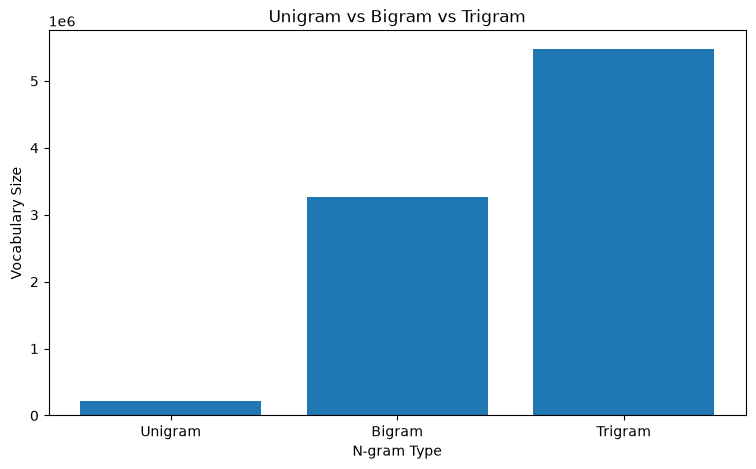

In [44]:
ngram_types = ['Unigram', 'Bigram', 'Trigram']

vocab_sizes = [
    unigram_features,
    bigram_features,
    trigram_features
]

plt.figure(figsize=(9, 5))

plt.bar(ngram_types, vocab_sizes)

plt.title("Unigram vs Bigram vs Trigram")
plt.xlabel("N-gram Type")
plt.ylabel("Vocabulary Size")

plt.show()

In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF Vectorizer
tfidf = TfidfVectorizer()

# Fit and transform movie reviews
X_tfidf = tfidf.fit_transform(df['remove_stopwords'])

# Display TF-IDF matrix
print("TF-IDF Matrix:")
print(X_tfidf)

# Vocabulary
print("\nTF-IDF Vocabulary:")
print(tfidf.get_feature_names_out())

# Vocabulary size
print("\nVocabulary Size:", len(tfidf.get_feature_names_out()))

# Matrix shape
print("\nTF-IDF Matrix Shape:", X_tfidf.shape)

TF-IDF Matrix:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4982653 stored elements and shape (50000, 214264)>
  Coords	Values
  (0, 133315)	0.017838267664123397
  (0, 156719)	0.06324985171169782
  (0, 117522)	0.055195246764872544
  (0, 205158)	0.06484931097827101
  (0, 136998)	0.3728115541002663
  (0, 59415)	0.0959862708824285
  (0, 212957)	0.04570545771145645
  (0, 88172)	0.0697558242843469
  (0, 157480)	0.07262459883368301
  (0, 61345)	0.048268529677246486
  (0, 82380)	0.04832443313880344
  (0, 118123)	0.08223629325945299
  (0, 68283)	0.05385883649718812
  (0, 188848)	0.03259839434807453
  (0, 180499)	0.13976783050457536
  (0, 24300)	0.07788367732813686
  (0, 198393)	0.09327427811667824
  (0, 162882)	0.03204878859711405
  (0, 202868)	0.19793958309584314
  (0, 167169)	0.03987664268725657
  (0, 210146)	0.04950564240163326
  (0, 76890)	0.03178522461974091
  (0, 195332)	0.06151858300833986
  (0, 129970)	0.050722729029090405
  (0, 169535)	0.10184960868805817
  :	:
  (499

In [48]:
import pandas as pd

tfidf_df = pd.DataFrame(
    X_tfidf[:5, :10].toarray(),
    columns=tfidf.get_feature_names_out()[:10]
)

print(tfidf_df.head())

    aa  aaa  aaaaaaaaaaaahhhhhhhhhhhhhh  aaaaaaaargh  aaaaaaah  \
0  0.0  0.0                         0.0          0.0       0.0   
1  0.0  0.0                         0.0          0.0       0.0   
2  0.0  0.0                         0.0          0.0       0.0   
3  0.0  0.0                         0.0          0.0       0.0   
4  0.0  0.0                         0.0          0.0       0.0   

   aaaaaaahhhhhhggg  aaaaagh  aaaaah  aaaaargh  aaaaarrrrrrgggggghhhhhh  
0               0.0      0.0     0.0       0.0                      0.0  
1               0.0      0.0     0.0       0.0                      0.0  
2               0.0      0.0     0.0       0.0                      0.0  
3               0.0      0.0     0.0       0.0                      0.0  
4               0.0      0.0     0.0       0.0                      0.0  


In [49]:
import numpy as np

# First review
review_vector = X_tfidf[0]

# Get non-zero feature indices
feature_indices = review_vector.indices

# Get TF-IDF scores
scores = review_vector.data

# Get vocabulary
words = tfidf.get_feature_names_out()

# Create DataFrame
word_scores = pd.DataFrame({
    'Word': words[feature_indices],
    'TF-IDF Score': scores
})

# Sort highest scores first
word_scores = word_scores.sort_values(
    by='TF-IDF Score',
    ascending=False
)

print(word_scores.head(10))

             Word  TF-IDF Score
4              oz      0.372812
18       violence      0.197940
118         wholl      0.185195
52         prison      0.181697
121       inmates      0.166941
91         forget      0.155537
14         struck      0.139768
98      romanceoz      0.124231
140  viewingthats      0.124231
63     manyaryans      0.124231
